In [25]:
import os
import io
import requests
import pandas as pd

# Create 'data' directory if it does not exist
os.makedirs('data', exist_ok=True)

file_path = 'data/eurostat_house_prices.csv'
url = "https://ec.europa.eu/eurostat/api/dissemination/sdmx/2.1/data/prc_hpi_a?format=SDMX-CSV"

# Check if file is already downloaded locally
if os.path.exists(file_path):
    print("Loading cached dataset from local storage...")
    df = pd.read_csv(file_path)
    print("Data loaded successfully!")
else:
    print("Downloading dataset from Eurostat API...")
    # Fetch data directly bypassing local SSL certificate verification
    response = requests.get(url, verify=False)
    
    if response.status_code == 200:
        df = pd.read_csv(io.StringIO(response.text))
        # Save to local CSV file
        df.to_csv(file_path, index=False)
        print("Success! Dataset downloaded and saved to 'data/eurostat_house_prices.csv'.")
    else:
        print(f"Failed to download data. HTTP Status Code: {response.status_code}")

# Display dataset dimensions and first few rows
print(f"\nDataset shape: {df.shape}")
display(df.head())

Loading cached dataset from local storage...
Data loaded successfully!

Dataset shape: (6114, 10)


,DATAFLOW,LAST UPDATE,freq,purchase,unit,geo,TIME_PERIOD,OBS_VALUE,OBS_FLAG,CONF_STATUS
0,ESTAT:PRC_HPI_A(1.0),01/10/26 11:00:00,A,DW_EXST,I15_A_AVG,AT,2010,77.75,NaN,NaN
1,ESTAT:PRC_HPI_A(1.0),01/10/26 11:00:00,A,DW_EXST,I15_A_AVG,AT,2011,81.97,NaN,NaN
2,ESTAT:PRC_HPI_A(1.0),01/10/26 11:00:00,A,DW_EXST,I15_A_AVG,AT,2012,86.81,NaN,NaN
3,ESTAT:PRC_HPI_A(1.0),01/10/26 11:00:00,A,DW_EXST,I15_A_AVG,AT,2013,91.14,NaN,NaN
4,ESTAT:PRC_HPI_A(1.0),01/10/26 11:00:00,A,DW_EXST,I15_A_AVG,AT,2014,94.53,NaN,NaN


In [26]:
print("Kolumny w tabeli:")
print(df.columns.tolist())
print("\nWymiary tabeli:", df.shape)
display(df.head())

Kolumny w tabeli:
['DATAFLOW', 'LAST UPDATE', 'freq', 'purchase', 'unit', 'geo', 'TIME_PERIOD', 'OBS_VALUE', 'OBS_FLAG', 'CONF_STATUS']

Wymiary tabeli: (6114, 10)


,DATAFLOW,LAST UPDATE,freq,purchase,unit,geo,TIME_PERIOD,OBS_VALUE,OBS_FLAG,CONF_STATUS
0,ESTAT:PRC_HPI_A(1.0),01/10/26 11:00:00,A,DW_EXST,I15_A_AVG,AT,2010,77.75,NaN,NaN
1,ESTAT:PRC_HPI_A(1.0),01/10/26 11:00:00,A,DW_EXST,I15_A_AVG,AT,2011,81.97,NaN,NaN
2,ESTAT:PRC_HPI_A(1.0),01/10/26 11:00:00,A,DW_EXST,I15_A_AVG,AT,2012,86.81,NaN,NaN
3,ESTAT:PRC_HPI_A(1.0),01/10/26 11:00:00,A,DW_EXST,I15_A_AVG,AT,2013,91.14,NaN,NaN
4,ESTAT:PRC_HPI_A(1.0),01/10/26 11:00:00,A,DW_EXST,I15_A_AVG,AT,2014,94.53,NaN,NaN


In [27]:
#filter for Poland, Total market, base index
df_pl = df[(df['geo'] == 'PL') & (df['purchase'] == 'TOTAL') & (df['unit'] == 'I15_R2')]

#sort data chronologicaly by year
df_pl = df_pl.sort_values('TIME_PERIOD')

print("--- House Price Index in Poland (2015 = 100) ---")
display(df_pl[['TIME_PERIOD', 'OBS_VALUE']])

--- House Price Index in Poland (2015 = 100) ---


,TIME_PERIOD,OBS_VALUE


In [28]:
#inspect unique values in filter columns for Poland
pl_data = df[df['geo'] == 'PL']

print("Available values in 'unit' for Poland:")
print(pl_data['unit'].unique())

print("\nAvailable values in 'purchase' for Poland:")
print(pl_data['purchase'].unique())

Available values in 'unit' for Poland:
<StringArray>
['I15_A_AVG', 'I25_A_AVG', 'RCH_A_AVG']
Length: 3, dtype: str

Available values in 'purchase' for Poland:
<StringArray>
['DW_EXST', 'DW_NEW', 'TOTAL']
Length: 3, dtype: str


In [29]:
import pandas as pd
import matplotlib.pyplot as plt

#Filter dataset for Poland, total housing market, and 2015 annual average base index
df_pl = df[
    (df['geo'] == 'PL') & 
    (df['purchase'] == 'TOTAL') & 
    (df['unit'] == 'I15_A_AVG')
].copy()

#Ensure correct data types
df_pl['TIME_PERIOD'] = pd.to_numeric(df_pl['TIME_PERIOD'], errors='coerce')
df_pl['OBS_VALUE'] = pd.to_numeric(df_pl['OBS_VALUE'], errors='coerce')

#drop missing values and sort chronologically
df_pl = df_pl.dropna(subset=['TIME_PERIOD', 'OBS_VALUE']).sort_values('TIME_PERIOD')

#display filtered data
print(f"Data successfully filtered! Total records for Poland: {len(df_pl)}")
display(df_pl[['TIME_PERIOD', 'OBS_VALUE']])

Data successfully filtered! Total records for Poland: 16


,TIME_PERIOD,OBS_VALUE
4465,2010,105.61
4466,2011,105.70
4467,2012,102.01
4468,2013,97.54
4469,2014,98.50
4470,2015,100.00
4471,2016,101.86
4472,2017,105.78
4473,2018,112.74
4474,2019,122.52


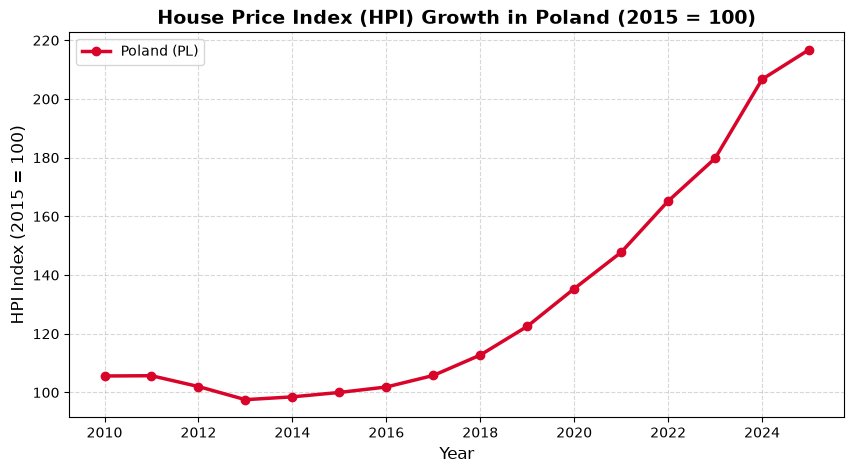

In [30]:

plt.figure(figsize=(10, 5))

#Plot housing price trend line
plt.plot(
    df_pl['TIME_PERIOD'], 
    df_pl['OBS_VALUE'], 
    marker='o', 
    color='#d90429', 
    linewidth=2.5, 
    label='Poland (PL)'
)

#Customizing plot aesthetics
plt.title('House Price Index (HPI) Growth in Poland (2015 = 100)', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('HPI Index (2015 = 100)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper left')

# Render plot
plt.show()

In [ ]:
git add analysis.ipynb data/
git commit -m "feat: add data ingestion script and initial Poland HPI chart"
git push origin main